<a href="https://colab.research.google.com/github/swagatabanerjee/QML-Course-Practice/blob/main/Quantum_Error_Correction_with_qiskit_qec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
# Install core Qiskit, Qiskit Aer, Qiskit Algorithms, and Qiskit Machine Learning
!pip install qiskit qiskit-aer qiskit-algorithms qiskit-machine-learning pylatexenc matplotlib scikit-learn

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit_algorithms.optimizers import COBYLA
from qiskit_machine_learning.algorithms import VQC
from qiskit.primitives import StatevectorSampler as Sampler
from IPython.display import clear_output

# 1. Generate Synthetic QEC Syndrome Data (Simplified for Demo)
# Let's assume a 3-qubit bit-flip code where syndromes are 2-bit strings.
# Features: [Syndrome_1, Syndrome_2]
# Labels: 0 (No Error/I), 1 (Error on Q1), 2 (Error on Q2), 3 (Error on Q3)

np.random.seed(42)
num_samples = 100

# Synthetic features (syndrome measurements) and labels (error types)
X = np.random.uniform(-1, 1, (num_samples, 2))
y = np.array([0 if x[0] > 0 and x[1] > 0 else
              1 if x[0] < 0 and x[1] > 0 else
              2 if x[0] > 0 and x[1] < 0 else 3 for x in X])

# For a faster demo, let's make it binary: Error (1) vs No Error (0)
y_binary = np.array([0 if label == 0 else 1 for label in y])

X_train, X_test, y_train, y_test = train_test_split(X, y_binary, test_size=0.2, random_state=42)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

Training samples: 80
Testing samples: 20


In [26]:
from sklearn.svm import SVC

# 1. Initialize and train the classical Support Vector Machine (RBF kernel)
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)
svm_model.fit(X_train, y_train)

# 2. Evaluate performance
svm_train_score = svm_model.score(X_train, y_train)
svm_test_score = svm_model.score(X_test, y_test)

print(f"Classical SVM Training Accuracy: {svm_train_score * 100:.2f}%")
print(f"Classical SVM Testing Accuracy:  {svm_test_score * 100:.2f}%")


Classical SVM Training Accuracy: 98.75%
Classical SVM Testing Accuracy:  85.00%


In [27]:
# 2. Setup the Quantum Machine Learning Model
num_features = X.shape[1]

# Feature Map: Encodes classical syndrome data into quantum states using functional builder
feature_map = zz_feature_map(num_features, reps=1)

# Ansatz: The trainable quantum circuit (variational form) using functional builder
ansatz = real_amplitudes(num_features, reps=2)

# List to store objective function values
objective_func_vals = []

# We define a custom callback for the VQC
def callback_graph(weights, obj_func_eval):
    objective_func_vals.append(obj_func_eval)

# Optimizer for the classical feedback loop
optimizer = COBYLA(maxiter=40)
sampler = Sampler()

# 3. Initialize and Train the Variational Quantum Classifier (VQC)
print("Initializing Quantum Classifier... (this will take a minute or two)")
vqc = VQC(
    sampler=sampler,
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=optimizer,
    callback=callback_graph
)

# Let's patch the fit to guarantee we capture the objective value manually if VQC's callback fails
original_objective = vqc._get_objective
def patched_objective(*args, **kwargs):
    obj = original_objective(*args, **kwargs)
    def wrapped_obj(weights):
        val = obj(weights)
        # Since the loss is returned here, we can record it
        objective_func_vals.append(float(val))
        return val
    return wrapped_obj

vqc._get_objective = patched_objective

# Clear previous history and Train the model
objective_func_vals.clear()
vqc.fit(X_train, y_train)

# 4. Evaluate the Model
train_score = vqc.score(X_train, y_train)
test_score = vqc.score(X_test, y_test)

print(f"\n--- QML QEC Classification Results ---")
print(f"Quantum Training Accuracy: {train_score * 100:.2f}%")
print(f"Quantum Testing Accuracy:  {test_score * 100:.2f}%")

Initializing Quantum Classifier... (this will take a minute or two)

--- QML QEC Classification Results ---
Quantum Training Accuracy: 73.75%
Quantum Testing Accuracy:  60.00%


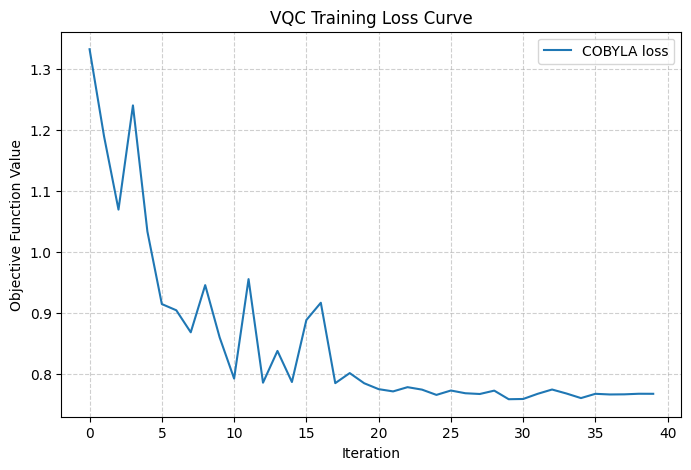

In [28]:
import matplotlib.pyplot as plt

if 'objective_func_vals' in globals() and len(objective_func_vals) > 0:
    plt.figure(figsize=(8, 5))
    plt.title("VQC Training Loss Curve")
    plt.xlabel("Iteration")
    plt.ylabel("Objective Function Value")
    plt.plot(range(len(objective_func_vals)), objective_func_vals, label='COBYLA loss', color='tab:blue')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.show()
else:
    print("No objective function values were recorded in 'objective_func_vals'. Please re-run the VQC training cell to populate the values.")

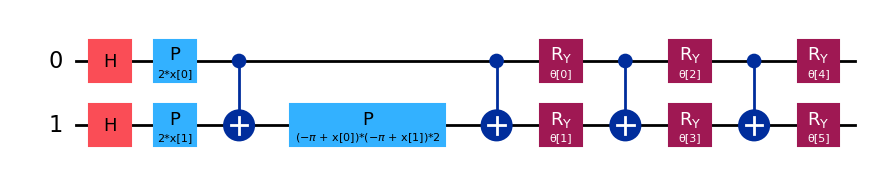

In [29]:
# Combine feature map and ansatz to visualize the full VQC circuit structure
vqc_circuit = feature_map.compose(ansatz)

# Draw the circuit using matplotlib representation
vqc_circuit.draw(output='mpl')

In [30]:
# 3. Print comparison
print("=== Classical SVM vs. Quantum VQC Performance ===")
print(f"Classical SVM Training Accuracy: {svm_train_score * 100:.2f}%")
print(f"Classical SVM Testing Accuracy:  {svm_test_score * 100:.2f}%")
print("-" * 46)
print(f"Quantum VQC Training Accuracy:   {train_score * 100:.2f}%")
print(f"Quantum VQC Testing Accuracy:    {test_score * 100:.2f}%")

=== Classical SVM vs. Quantum VQC Performance ===
Classical SVM Training Accuracy: 98.75%
Classical SVM Testing Accuracy:  85.00%
----------------------------------------------
Quantum VQC Training Accuracy:   73.75%
Quantum VQC Testing Accuracy:    60.00%
